In [42]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [43]:
df = pd.read_csv('ford.csv')

df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [44]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (17966, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.6 MB


In [45]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [46]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

Total Missing Values:
0


In [47]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 154


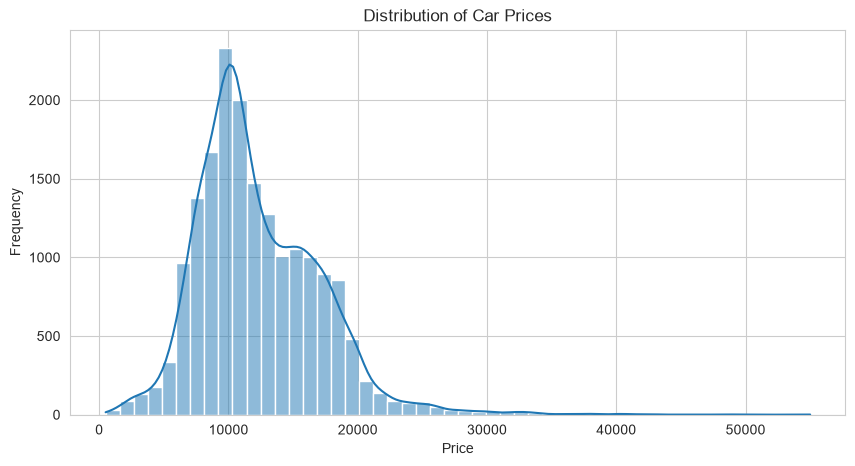

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='price',
    bins=50,
    kde=True
)

plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

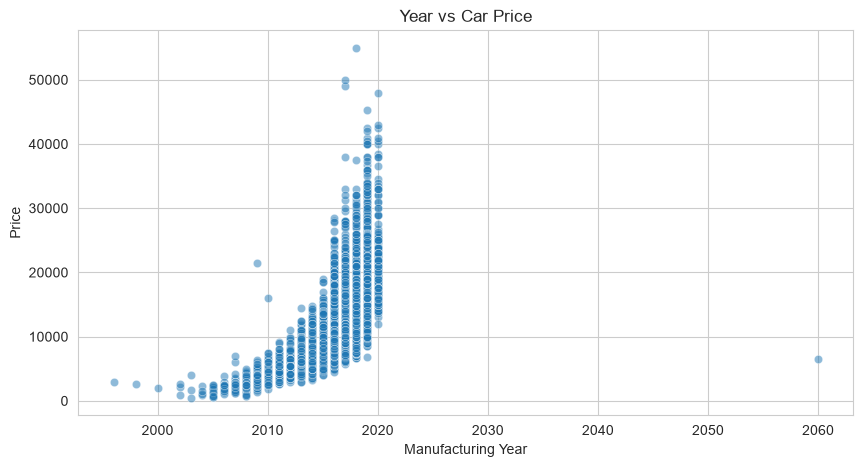

In [49]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='year',
    y='price',
    alpha=0.5
)

plt.title('Year vs Car Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price')

plt.show()

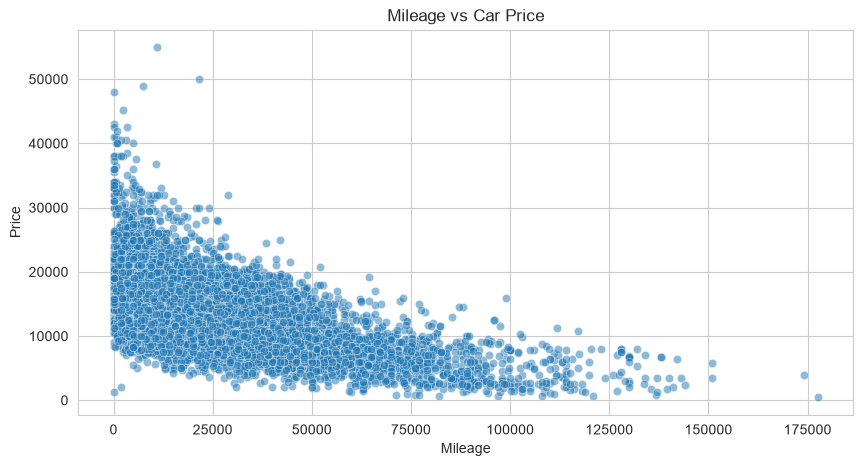

In [50]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='mileage',
    y='price',
    alpha=0.5
)

plt.title('Mileage vs Car Price')
plt.xlabel('Mileage')
plt.ylabel('Price')

plt.show()

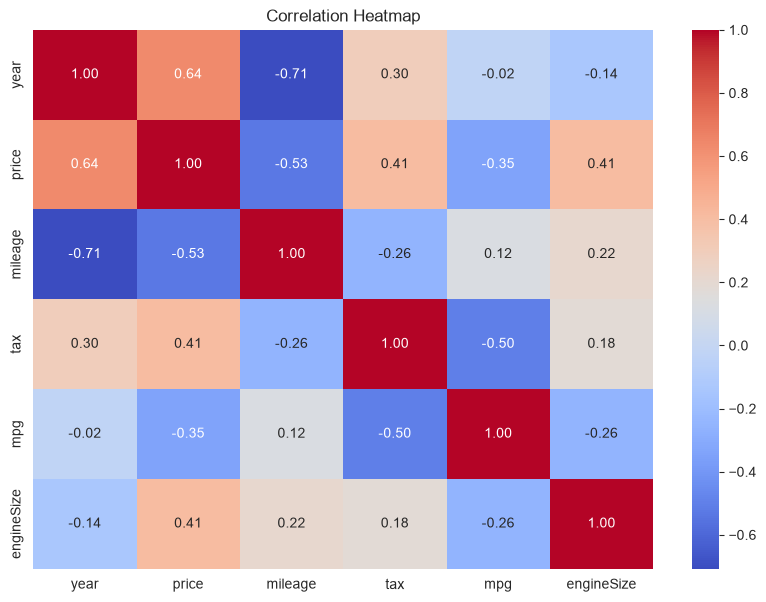

In [51]:
plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

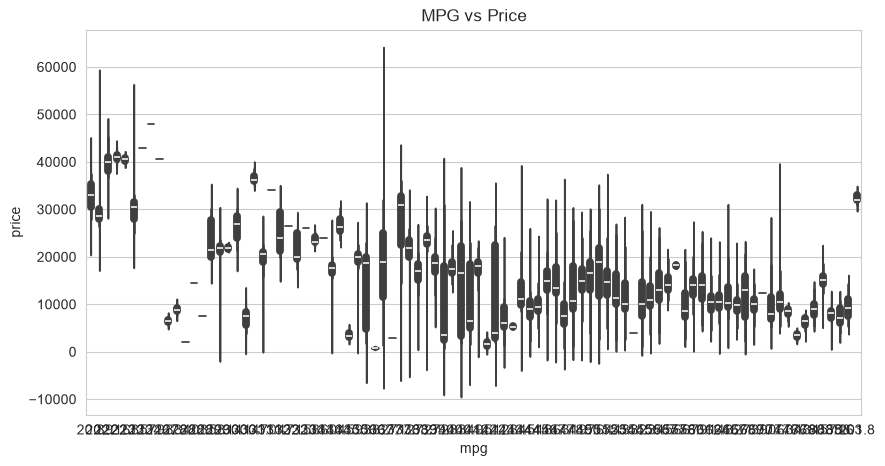

In [52]:
plt.figure(figsize=(10, 5))

sns.violinplot(
    data=df,
    x='mpg',
    y='price'
)

plt.title('MPG vs Price')

plt.show()

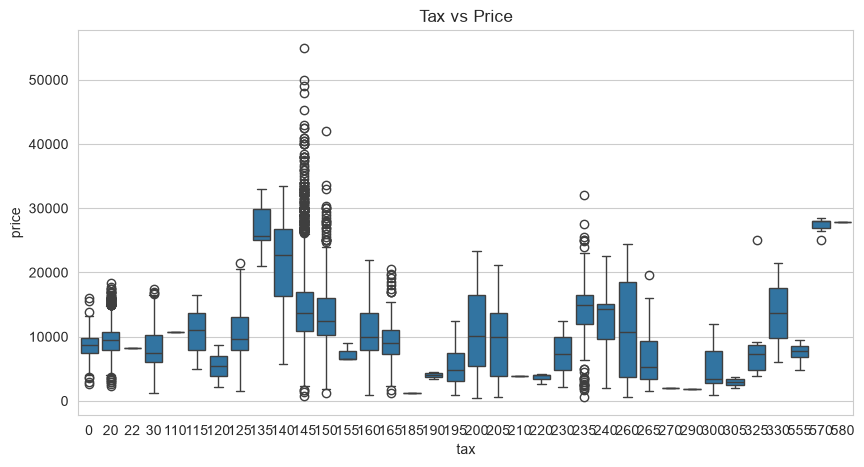

In [53]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='tax',
    y='price'
)

plt.title('Tax vs Price')

plt.show()

In [54]:
X = df.drop(columns=['price'])

y = df['price']

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (17966, 8)
Target Shape: (17966,)


In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (14372, 8)
Testing Data: (3594, 8)


In [56]:
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=['object']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['model', 'transmission', 'fuelType']

Numerical Features:
['year', 'mileage', 'tax', 'mpg', 'engineSize']


In [57]:
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.base import clone

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

In [58]:
numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),

        ('scaler', StandardScaler())
    ]
)

print("Numerical Pipeline Created!")

Numerical Pipeline Created!


In [59]:
onehot_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),

        ('encoder', OneHotEncoder(
            handle_unknown='ignore'
        ))
    ]
)

onehot_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),

        ('cat', onehot_pipeline, categorical_features)
    ]
)

print("One-Hot Preprocessor Created!")

One-Hot Preprocessor Created!


In [60]:
label_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),

        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]
)

label_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),

        ('cat', label_pipeline, categorical_features)
    ]
)

print("Label Encoding Preprocessor Created!")

Label Encoding Preprocessor Created!


In [61]:
from sklearn.linear_model import LinearRegression

from sklearn.linear_model import Ridge

from sklearn.ensemble import GradientBoostingRegressor

In [62]:
models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(
        alpha=1.0
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models Defined !")

Models Defined !


In [63]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

results = []

trained_models = {}

preprocessors = {
    'One-Hot Encoding': onehot_preprocessor,

    'Label Encoding': label_preprocessor
}

for encoding_name, preprocessor in preprocessors.items():

    for model_name, algorithm in models.items():

        model_pipeline = Pipeline(
            steps=[
                ('preprocessor', clone(preprocessor)),

                ('model', clone(algorithm))
            ]
        )

        # Training
        model_pipeline.fit(X_train, y_train)

        # Prediction
        y_pred = model_pipeline.predict(X_test)

        # Evaluation Metrics
        mae = mean_absolute_error(y_test, y_pred)

        mse = mean_squared_error(y_test, y_pred)

        rmse = np.sqrt(mse)

        r2 = r2_score(y_test, y_pred)

        # Number of features after encoding
        p = model_pipeline.named_steps[
            'preprocessor'
        ].transform(X_test).shape[1]

        # Number of test samples
        n = len(y_test)

        # Adjusted R2
        adjusted_r2 = 1 - (
            (1 - r2) * (n - 1) / (n - p - 1)
        )

        # Store Results
        results.append({
            'Encoding': encoding_name,

            'Model': model_name,

            'MAE': mae,

            'MSE': mse,

            'RMSE': rmse,

            'R2 Score': r2,

            'Adjusted R2': adjusted_r2
        })

        # Store Trained Model
        trained_models[
            (encoding_name, model_name)
        ] = model_pipeline

        print(f"\nEncoding: {encoding_name}")

        print(f"Model: {model_name}")

        print("--------------------------")

        print("MAE:", round(mae, 2))

        print("MSE:", round(mse, 2))

        print("RMSE:", round(rmse, 2))

        print("R2 Score:", round(r2, 4))

        print("Adjusted R2:", round(adjusted_r2, 4))


Encoding: One-Hot Encoding
Model: Linear Regression
--------------------------
MAE: 1374.81
MSE: 3454991.04
RMSE: 1858.76
R2 Score: 0.8458
Adjusted R2: 0.8442

Encoding: One-Hot Encoding
Model: Ridge Regression
--------------------------
MAE: 1374.3
MSE: 3446126.09
RMSE: 1856.37
R2 Score: 0.8462
Adjusted R2: 0.8446

Encoding: One-Hot Encoding
Model: Gradient Boosting
--------------------------
MAE: 962.58
MSE: 1860523.42
RMSE: 1364.01
R2 Score: 0.917
Adjusted R2: 0.9161

Encoding: Label Encoding
Model: Linear Regression
--------------------------
MAE: 1776.83
MSE: 5903593.74
RMSE: 2429.73
R2 Score: 0.7366
Adjusted R2: 0.736

Encoding: Label Encoding
Model: Ridge Regression
--------------------------
MAE: 1776.82
MSE: 5903541.09
RMSE: 2429.72
R2 Score: 0.7366
Adjusted R2: 0.736

Encoding: Label Encoding
Model: Gradient Boosting
--------------------------
MAE: 964.15
MSE: 1900091.98
RMSE: 1378.44
R2 Score: 0.9152
Adjusted R2: 0.915


In [64]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

results_df

,Encoding,Model,MAE,MSE,RMSE,R2 Score,Adjusted R2
2,One-Hot Encoding,Gradient Boosting,962.582792,1.860523e+06,1364.010051,0.916986,0.916122
5,Label Encoding,Gradient Boosting,964.153536,1.900092e+06,1378.438239,0.915220,0.915031
1,One-Hot Encoding,Ridge Regression,1374.295301,3.446126e+06,1856.374447,0.846238,0.844638
0,One-Hot Encoding,Linear Regression,1374.811164,3.454991e+06,1858.760619,0.845842,0.844238
4,Label Encoding,Ridge Regression,1776.822075,5.903541e+06,2429.720373,0.736591,0.736003
3,Label Encoding,Linear Regression,1776.825528,5.903594e+06,2429.731208,0.736588,0.736001


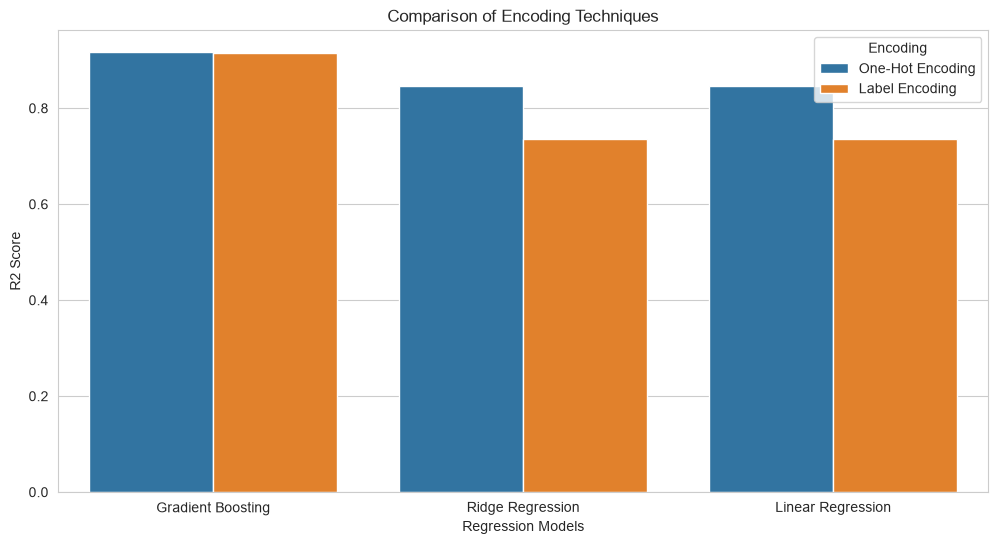

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score',
    hue='Encoding'
)

plt.title('Comparison of Encoding Techniques')

plt.xlabel('Regression Models')

plt.ylabel('R2 Score')

plt.show()

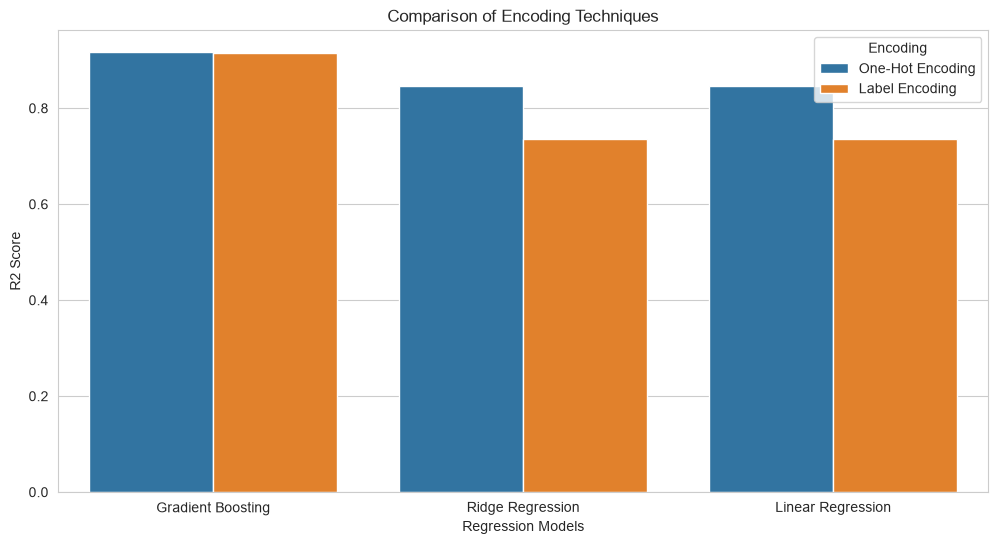

In [66]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score',
    hue='Encoding'
)

plt.title('Comparison of Encoding Techniques')

plt.xlabel('Regression Models')

plt.ylabel('R2 Score')

plt.show()

In [67]:
best_result = results_df.iloc[0]

best_encoding = best_result['Encoding']

best_model_name = best_result['Model']

best_model = trained_models[
    (best_encoding, best_model_name)
]

print("Best Encoding:", best_encoding)

print("Best Model:", best_model_name)

print("Best R2 Score:", round(best_result['R2 Score']*100, 4))

print("Best Adjusted R2:", round(best_result['Adjusted R2']*100, 4))

Best Encoding: One-Hot Encoding
Best Model: Gradient Boosting
Best R2 Score: 91.6986
Best Adjusted R2: 91.6122


In [68]:
y_pred = best_model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,

    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,6995,7308.226925
1,8999,9524.009064
2,7998,8177.786579
3,5491,6125.465009
4,3790,3236.224603
5,18200,17306.204686
6,22998,21125.507924
7,11000,11594.603057
8,7600,9532.256343
9,14985,17086.429407


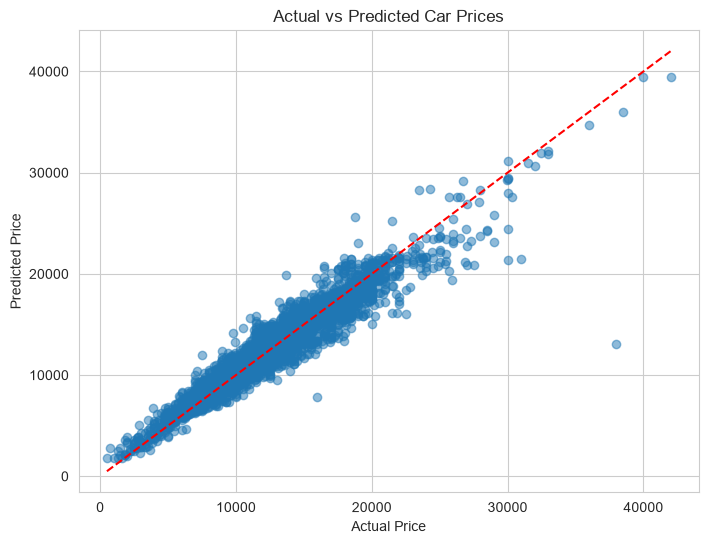

In [69]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Price')

plt.ylabel('Predicted Price')

plt.title('Actual vs Predicted Car Prices')

plt.show()

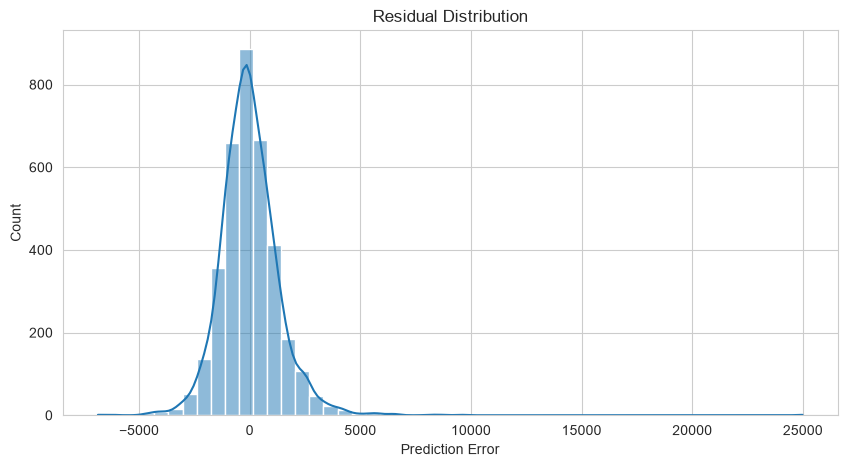

In [70]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.title('Residual Distribution')

plt.xlabel('Prediction Error')

plt.show()

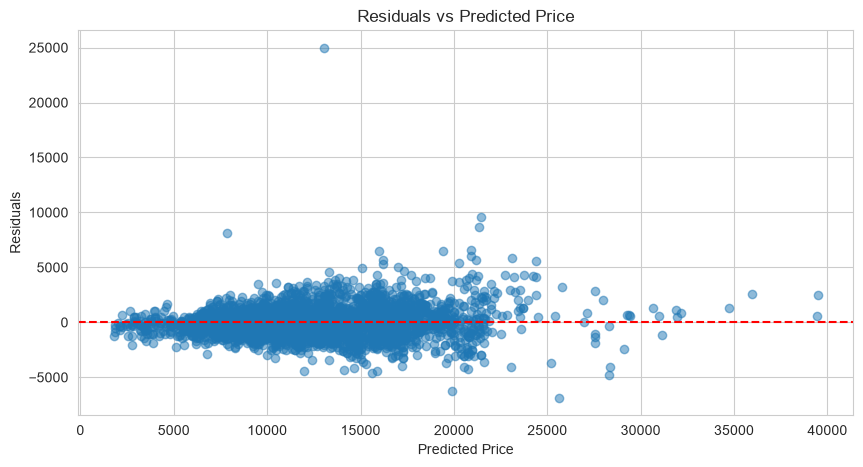

In [71]:
plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted Price')

plt.ylabel('Residuals')

plt.title('Residuals vs Predicted Price')

plt.show()

In [72]:
import joblib

joblib.dump(
    best_model,
    'ford_price_prediction_model.pkl'
)

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


In [73]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Feature Selection Libraries Imported!")

Feature Selection Libraries Imported!


In [74]:
feature_selection_models = {
    'Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(alpha=1.0),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [75]:
feature_selection_results = []

feature_selection_trained_models = {}

for model_name, algorithm in feature_selection_models.items():

    model_pipeline = Pipeline(
        steps=[
            ('preprocessor', clone(onehot_preprocessor)),

            ('feature_selection', SelectKBest(
                score_func=f_regression,
                k=10
            )),

            ('model', clone(algorithm))
        ]
    )

    # Training
    model_pipeline.fit(X_train, y_train)

    # Prediction
    y_pred = model_pipeline.predict(X_test)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    # Number of selected features
    p = 10

    n = len(y_test)

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - p - 1)
    )

    feature_selection_results.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2,
        'Adjusted R2': adjusted_r2
    })

    feature_selection_trained_models[
        model_name
    ] = model_pipeline

    print(f"\nModel: {model_name}")

    print("MAE:", round(mae, 2))

    print("RMSE:", round(rmse, 2))

    print("R2 Score:", round(r2, 4))

    print("Adjusted R2:", round(adjusted_r2, 4))


Model: Linear Regression
MAE: 1707.98
RMSE: 2368.72
R2 Score: 0.7497
Adjusted R2: 0.749

Model: Ridge Regression
MAE: 1707.7
RMSE: 2368.6
R2 Score: 0.7497
Adjusted R2: 0.749

Model: Gradient Boosting
MAE: 1025.53
RMSE: 1474.12
R2 Score: 0.903
Adjusted R2: 0.9028


In [76]:
feature_selection_df = pd.DataFrame(
    feature_selection_results
)

feature_selection_df = feature_selection_df.sort_values(
    by='R2 Score',
    ascending=False
)

feature_selection_df

,Model,MAE,MSE,RMSE,R2 Score,Adjusted R2
2,Gradient Boosting,1025.530472,2.173034e+06,1474.121503,0.903042,0.902771
1,Ridge Regression,1707.698678,5.610274e+06,2368.601622,0.749676,0.748977
0,Linear Regression,1707.983284,5.610841e+06,2368.721311,0.749651,0.748952


In [79]:
original_results = results_df[
    results_df['Encoding'] == 'One-Hot Encoding'
].copy()

original_results['Feature Selection'] = 'Without Selection'

feature_selection_df = feature_selection_df.copy()

feature_selection_df['Encoding'] = 'One-Hot Encoding'

feature_selection_df['Feature Selection'] = 'With Selection'

comparison_df = pd.concat(
    [original_results, feature_selection_df],
    ignore_index=True
)

comparison_df

,Encoding,Model,MAE,MSE,RMSE,R2 Score,Adjusted R2,Feature Selection
0,One-Hot Encoding,Gradient Boosting,962.582792,1.860523e+06,1364.010051,0.916986,0.916122,Without Selection
1,One-Hot Encoding,Ridge Regression,1374.295301,3.446126e+06,1856.374447,0.846238,0.844638,Without Selection
2,One-Hot Encoding,Linear Regression,1374.811164,3.454991e+06,1858.760619,0.845842,0.844238,Without Selection
3,One-Hot Encoding,Gradient Boosting,1025.530472,2.173034e+06,1474.121503,0.903042,0.902771,With Selection
4,One-Hot Encoding,Ridge Regression,1707.698678,5.610274e+06,2368.601622,0.749676,0.748977,With Selection
5,One-Hot Encoding,Linear Regression,1707.983284,5.610841e+06,2368.721311,0.749651,0.748952,With Selection


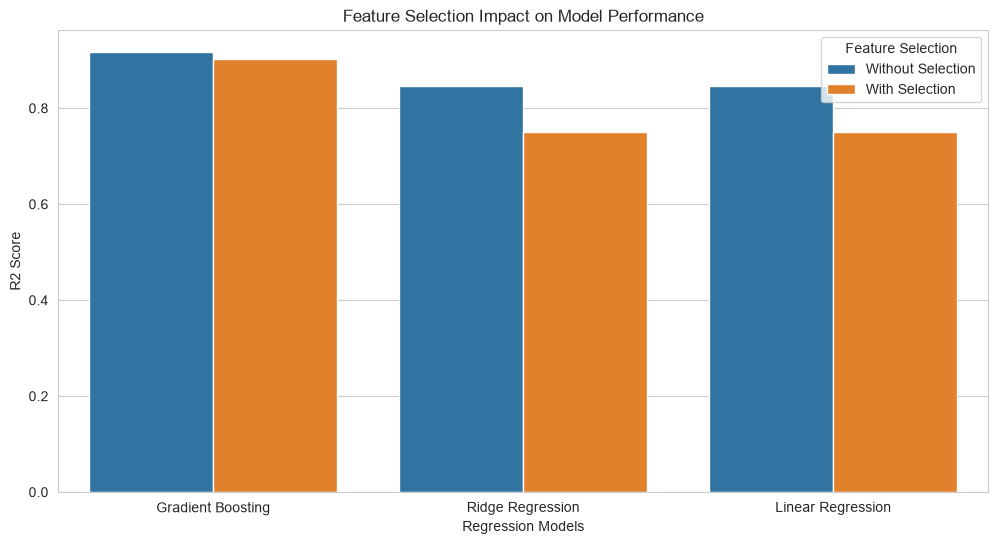

In [78]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='R2 Score',
    hue='Feature Selection'
)

plt.title('Feature Selection Impact on Model Performance')

plt.xlabel('Regression Models')

plt.ylabel('R2 Score')

plt.show()